# 04. LightGBM day-ahead system

Verdict: With RTE's forecast as a feature, LightGBM beats RTE raw on all three scopes, mostly by correcting RTE's usual error by hour. Without RTE, our honest model stays far behind. MAE test: LightGBM + RTE 908 MW vs RTE raw 1,439 MW (-36.9 %).

Setup: Cutoff D 12:00, forecast the 24 h of D+1, test 1 Jul 2025 to 30 Jun 2026.

## 1. Setup

One model for the 24 hours of D+1. Load is known up to D 11:00, so every lag is at least 48 h. Choices are made on a
walk-forward over 4 quarterly folds (July 2024 to June 2025), the test year is left alone. MAEs are hourly, in MW.

In [1]:
import sys
sys.path.insert(0, "../src")

from datetime import date

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from watt_forecast.data_preprocessing import load_dataset, save_predictions
from watt_forecast.features import make_features, feature_cols
from watt_forecast.metrics import compute_metrics, evaluate, scorecard
from watt_forecast.models.baseline import naive_forecast
from watt_forecast.models.gbm import fit_lgbm, predict, walk_forward, first_changed_row

TRAIN_END = date(2025, 6, 30)
TEST_START, TEST_END = date(2025, 7, 1), date(2026, 6, 30)
FOLDS = [
    (date(2024, 7, 1), date(2024, 9, 30)),
    (date(2024, 10, 1), date(2024, 12, 31)),
    (date(2025, 1, 1), date(2025, 3, 31)),
    (date(2025, 4, 1), date(2025, 6, 30)),
]
FOLD_NAMES = ["Q3_2024", "Q4_2024", "Q1_2025", "Q2_2025"]

pl.Config.set_tbl_rows(30)
plt.rcParams["figure.figsize"] = (12, 4)

In [2]:
df = load_dataset()

tables = {
    "none": make_features(df, "none"),
    "persistence": make_features(df, "persistence"),
    "persistence + RTE": make_features(df, "persistence", with_rte=True),
    "observed": make_features(df, "observed"),
}
assert all(t.height == df.height for t in tables.values()), "one row per hour"
assert FOLDS[-1][1] == TRAIN_END < TEST_START, "the validation folds must end before the test period"
print(feature_cols(tables["persistence + RTE"]))

['lag_48', 'lag_72', 'lag_168', 'lag_336', 'roll_mean_24', 'roll_mean_168', 'hour', 'weekday', 'month', 'holiday', 'day_after_holiday', 'day_before_holiday', 'temp_lag_48', 'rte_forecast']


## 2. Model

Four models on the same lags and calendar: a linear regression (no temperature), LightGBM with the temperature of
2 days ago (persistence), LightGBM + RTE's forecast, and LightGBM with observed temperature (upper bound only).

### Perturbation test

Add 10,000 MW at hour s and rebuild the features. With the cutoff respected, the first changed row should be s + 48.

In [3]:
small = df.tail(2000)
s = 500

for name, mode, rte in [("none", "none", False), ("persistence + RTE", "persistence", True), ("observed", "observed", False)]:
    first = first_changed_row(lambda d: make_features(d, mode, with_rte=rte), small, s)
    print(f"{name:18s} first changed row: {first}")
    assert first == s + 48, f"{name}: the first changed row should be s + 48"

leaky = lambda d: make_features(d, "persistence").with_columns(pl.col("target").rolling_mean(24).alias("bad"))
print(f"{'leaky feature':18s} first changed row: {first_changed_row(leaky, small, s)}")
assert first_changed_row(leaky, small, s) == s, "a rolling mean without shift must be detected"

none               first changed row: 548
persistence + RTE  first changed row: 548
observed           first changed row: 548
leaky feature      first changed row: 500


### Linear regression

Lags, rolling means, one-hot calendar and holiday flags. No temperature. Coefficients are in the appendix.

In [4]:
def linear_table(table):
    """Lags + one-hot calendar, without temperature."""
    return table.drop("temp_lag_48").to_dummies(["hour", "weekday", "month"], drop_first=True)


def fit_linear(X, y, params=None):
    return LinearRegression().fit(X.to_numpy(), y.to_numpy())


lin = linear_table(tables["persistence"])

### Training period and hyperparameters

Tuned on the folds with LightGBM persistence: start in 2019 or 2023 (after the drop seen in 00_eda), three parameter sets.

In [5]:
PARAM_SETS = {
    "small (15 leaves, lr 0.1, 300 trees)": dict(num_leaves=15, learning_rate=0.1, n_estimators=300),
    "medium (31 leaves, lr 0.05, 500 trees)": dict(num_leaves=31, learning_rate=0.05, n_estimators=500),
    "large (63 leaves, lr 0.03, 1000 trees)": dict(num_leaves=63, learning_rate=0.03, n_estimators=1000),
}
TRAIN_STARTS = {"since 2019": date(2019, 1, 1), "since 2023": date(2023, 1, 1)}

rows = []
for start_name, start in TRAIN_STARTS.items():
    table = tables["persistence"].filter(pl.col("date") >= start)
    for param_name, params in PARAM_SETS.items():
        scores = walk_forward(table, FOLDS, params)
        rows.append({"train": start_name, "params": param_name, **dict(zip(FOLD_NAMES, scores)), "mean": np.mean(scores)})

choice = pl.DataFrame(rows).sort("mean")
TRAIN_START = TRAIN_STARTS[choice["train"][0]]
PARAMS = PARAM_SETS[choice["params"][0]]
print("chosen:", choice["train"][0], "|", choice["params"][0])
choice.with_columns(pl.col(FOLD_NAMES + ["mean"]).round(0))

chosen: since 2019 | medium (31 leaves, lr 0.05, 500 trees)


train,params,Q3_2024,Q4_2024,Q1_2025,Q2_2025,mean
str,str,f64,f64,f64,f64,f64
"""since 2019""","""medium (31 leaves, lr 0.05, 50…",816.0,2272.0,3054.0,1224.0,1841.0
"""since 2019""","""large (63 leaves, lr 0.03, 100…",775.0,2336.0,3062.0,1194.0,1842.0
"""since 2019""","""small (15 leaves, lr 0.1, 300 …",852.0,2255.0,3049.0,1264.0,1855.0
"""since 2023""","""medium (31 leaves, lr 0.05, 50…",951.0,2603.0,3395.0,1314.0,2066.0
"""since 2023""","""large (63 leaves, lr 0.03, 100…",937.0,2604.0,3398.0,1328.0,2067.0
"""since 2023""","""small (15 leaves, lr 0.1, 300 …",973.0,2641.0,3419.0,1347.0,2095.0


Training period matters way more than hyperparameters. Starting in 2019 wins on every fold (about 225 MW on average),
mostly in winter (Q4 2024: 2,272 vs 2,603 MW). The three parameter sets are within 15 MW, so noise. We keep 31 leaves,
lr 0.05, 500 trees.

### Fit on the test year

Each model is trained once up to 30 June 2025, then predicts every test day.

In [6]:
def fit_and_predict(table, fit=fit_lgbm, params=None):
    """Train from TRAIN_START to TRAIN_END, return the model and its predictions on the test year."""
    cols = feature_cols(table)
    train = table.filter(pl.col("date").is_between(TRAIN_START, TRAIN_END)).drop_nulls("lag_336")
    test_rows = table.filter(pl.col("date").is_between(TEST_START, TEST_END))
    assert train["date"].max() < test_rows["date"].min(), "training rows must come before the test"
    model = fit(train.select(cols), train["target"], params)
    return model, predict(model, test_rows.select(cols))


test = naive_forecast(df, lag_days=7).filter(pl.col("date").is_between(TEST_START, TEST_END))
assert test.height == 365 * 24, "the test period should have 8,760 hours"

_, pred_lin = fit_and_predict(lin, fit=fit_linear)
_, pred_persist = fit_and_predict(tables["persistence"], params=PARAMS)
model_rte, pred_rte = fit_and_predict(tables["persistence + RTE"], params=PARAMS)
_, pred_observed = fit_and_predict(tables["observed"], params=PARAMS)

test = test.with_columns(
    pl.Series("pred_linear", pred_lin),
    pl.Series("pred_lgbm_persist", pred_persist),
    pl.Series("pred_lgbm_rte", pred_rte),
    pl.Series("pred_lgbm_observed", pred_observed),
)

In [7]:
# Test forecasts of this notebook, read by 06_comparison
forecasts = {
    "Linear regression": "pred_linear",
    "LightGBM persistence": "pred_lgbm_persist",
    "LightGBM + RTE": "pred_lgbm_rte",
    "LightGBM observed temp. (UPPER BOUND, not available)": "pred_lgbm_observed",
}
save_predictions(test, forecasts, "04_lightgbm")

## 3. Results vs benchmark

In [8]:
scorecard(test, {"RTE raw": "rte_forecast_j1_mw", **forecasts})

forecast,global,evening_peak_18-20h,evening_peak_cold_days,vs_reference_(%)
str,f64,f64,f64,f64
"""RTE raw""",1439.0,1348.0,2307.0,0.0
"""Linear regression""",2299.0,2279.0,4867.0,59.8
"""LightGBM persistence""",2010.0,2036.0,4466.0,39.7
"""LightGBM + RTE""",908.0,984.0,2010.0,-36.9
"""LightGBM observed temp. (UPPER…",1184.0,1220.0,2170.0,-17.7


What we see. Without RTE, our best honest model (LightGBM persistence, 2,010 MW) is far behind RTE raw (1,439 MW),
and only the upper bound (1,184 MW) beats it. With RTE as a feature we get 908 MW (-36.9 %). Smaller gain on cold
evening peaks (2,010 vs 2,307 MW).

## 4. Where it fails

A cold week: 5 to 11 January 2026.

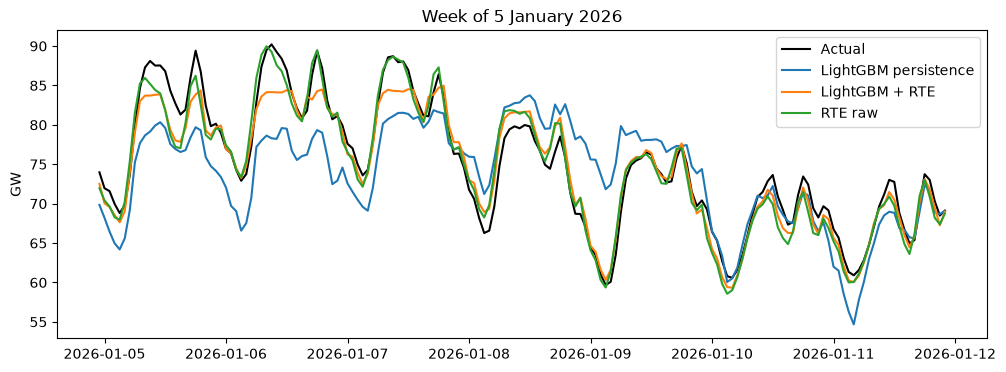

In [9]:
week = test.filter(pl.col("date").is_between(date(2026, 1, 5), date(2026, 1, 11)))

plt.plot(week["datetime_local"], week["target"] / 1000, color="k", label="Actual")
plt.plot(week["datetime_local"], week["pred_lgbm_persist"] / 1000, label="LightGBM persistence")
plt.plot(week["datetime_local"], week["pred_lgbm_rte"] / 1000, label="LightGBM + RTE")
plt.plot(week["datetime_local"], week["rte_forecast_j1_mw"] / 1000, label="RTE raw")
plt.title("Week of 5 January 2026")
plt.ylabel("GW")
plt.legend()
plt.show()

LightGBM persistence lags by a day and misses the 5-7 January peaks by about 10 GW. LightGBM + RTE follows RTE but
its peaks stay flat near 84 GW while the load hits 88-90 GW. Trees can't go above what they've seen, so they cut peaks.

## 5. Conclusion

- Question 1. Own data only: no (2,010 vs 1,439 MW). With RTE as a feature: yes, 908 MW on the test and better on
  all 4 folds (860 vs 1,362 MW).
- The gain is mostly a per-hour correction of RTE, smallest on cold evening peaks. It only holds if RTE publishes
  before 12:00 (to check).
- Next: a LightGBM on the residual (load - RTE) to keep RTE's peaks, plus prediction intervals.

## Appendix

### A.1 Example feature row

In [10]:
# Example row: 15 January 2026, 19:00 local time
example = tables["persistence + RTE"].filter((pl.col("date") == date(2026, 1, 15)) & (pl.col("hour") == 19))
assert example.height == 1, "one row for a given local date and hour"
example.drop("datetime_utc", "date").transpose(include_header=True, column_names=["15_Jan_2026_19:00"])

column,15_Jan_2026_19:00
str,f64
"""target""",69076.0
"""lag_48""",70266.0
"""lag_72""",74509.0
"""lag_168""",78528.0
"""lag_336""",71747.0
"""roll_mean_24""",65289.0
"""roll_mean_168""",71297.130952
"""hour""",19.0
"""weekday""",4.0


The model sees lag_48 (13 January 19:00) and older, rolling means ending 48 h before, the calendar, the 13 January
temperature (10.9 °C) and RTE's forecast (67.5 GW, actual 69.1 GW). Nothing from 14 or 15 January.

### A.2 Linear regression coefficients

In [11]:
lin_train = lin.filter(pl.col("date") <= TRAIN_END).drop_nulls("lag_336")
lin_model = fit_linear(lin_train.select(feature_cols(lin)), lin_train["target"])

lag_coefs = pl.DataFrame({"feature": feature_cols(lin), "coef": lin_model.coef_}).filter(
    pl.col("feature").str.starts_with("lag_") | pl.col("feature").str.starts_with("roll_")
)
print(f"sum of the lag and rolling-mean coefficients: {lag_coefs['coef'].sum():.3f}")
lag_coefs.with_columns(pl.col("coef").round(3))

sum of the lag and rolling-mean coefficients: 0.785


feature,coef
str,f64
"""lag_48""",0.393
"""lag_72""",0.022
"""lag_168""",0.461
"""lag_336""",0.086
"""roll_mean_24""",0.483
"""roll_mean_168""",-0.66


lag_168 (0.46) and lag_48 (0.39) do most of the work, lag_72 and lag_336 almost nothing. The rolling means
have opposite signs (+0.48 on 24 h, -0.66 on 168 h), a crude trend term. Coefficients sum to 0.79, the intercept and
month dummies give the rest.

### A.3 Model comparison on the walk-forward folds

Seasonal naive = lag_168.

In [12]:
def since_start(table):
    return table.filter(pl.col("date") >= TRAIN_START)


cv = {
    "Seasonal naive (lag 7d)": [
        compute_metrics(tables["none"].filter(pl.col("date").is_between(a, b)), "lag_168")["MAE"] for a, b in FOLDS
    ],
    "Linear regression": walk_forward(since_start(lin), FOLDS, None, fit=fit_linear),
    "LightGBM no temperature": walk_forward(since_start(tables["none"]), FOLDS, PARAMS),
    "LightGBM persistence": walk_forward(since_start(tables["persistence"]), FOLDS, PARAMS),
    "LightGBM + RTE": walk_forward(since_start(tables["persistence + RTE"]), FOLDS, PARAMS),
}

# RTE on the same folds, for reference (no training)
cv["RTE raw"] = [compute_metrics(df.filter(pl.col("date").is_between(a, b)), "rte_forecast_j1_mw")["MAE"] for a, b in FOLDS]

cv_table = pl.DataFrame(
    [{"model": name, **dict(zip(FOLD_NAMES, scores)), "mean": np.mean(scores), "std": np.std(scores)} for name, scores in cv.items()]
)
cv_table.with_columns(pl.exclude("model").round(0))

model,Q3_2024,Q4_2024,Q1_2025,Q2_2025,mean,std
str,f64,f64,f64,f64,f64,f64
"""Seasonal naive (lag 7d)""",1364.0,3625.0,6152.0,2200.0,3335.0,1816.0
"""Linear regression""",1373.0,2571.0,3144.0,1730.0,2204.0,695.0
"""LightGBM no temperature""",825.0,2238.0,3109.0,1229.0,1850.0,890.0
"""LightGBM persistence""",816.0,2272.0,3054.0,1224.0,1841.0,879.0
"""LightGBM + RTE""",620.0,982.0,1027.0,813.0,860.0,160.0
"""RTE raw""",1140.0,1381.0,1369.0,1560.0,1362.0,149.0


Without RTE, errors swing a lot: LightGBM persistence goes from 816 MW in summer (Q3 2024, better than RTE raw at
1,140 MW) to 3,054 MW in winter (Q1 2025). Lagged temperature barely helps (1,841 vs 1,850 MW). Models with RTE are
much more stable (std about 150 MW).

### A.4 All metrics on the test year

In [13]:
all_forecasts = {"Lag 7d": "pred_lag7d", "RTE raw": "rte_forecast_j1_mw", **forecasts}
results = pl.concat(
    [evaluate(test, col).with_columns(pl.lit(name).alias("forecast")) for name, col in all_forecasts.items()]
)
results = results.select("forecast", "scope", "MAE", "RMSE", "MAPE", "bias")
results.with_columns(pl.col("MAE", "RMSE", "bias").round(0), pl.col("MAPE").round(2))

forecast,scope,MAE,RMSE,MAPE,bias
str,str,f64,f64,f64,f64
"""Lag 7d""","""global""",3425.0,5060.0,6.4,-53.0
"""Lag 7d""","""evening_peak_18-20h""",3612.0,5227.0,6.39,-54.0
"""Lag 7d""","""evening_peak_18-20h_cold_days""",9225.0,10910.0,12.62,-8692.0
"""RTE raw""","""global""",1439.0,1783.0,2.86,-1086.0
"""RTE raw""","""evening_peak_18-20h""",1348.0,1681.0,2.49,-850.0
"""RTE raw""","""evening_peak_18-20h_cold_days""",2307.0,2773.0,3.22,-2004.0
"""Linear regression""","""global""",2299.0,3108.0,4.45,154.0
"""Linear regression""","""evening_peak_18-20h""",2279.0,3052.0,4.1,140.0
"""Linear regression""","""evening_peak_18-20h_cold_days""",4867.0,5715.0,6.7,-4863.0


Same picture as validation. LightGBM + RTE also wins on the evening peak (984 vs 1,348 MW), but on cold evening peaks
it keeps a -1,888 MW bias. Only 81 hours, but the expensive ones.

### A.5 MAE by hour and by month

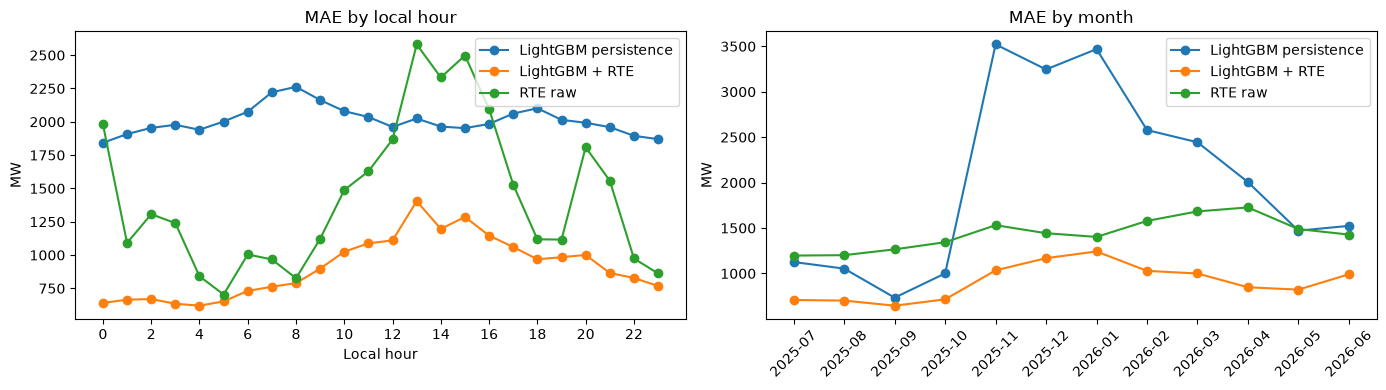

In [14]:
compared = {"LightGBM persistence": "pred_lgbm_persist", "LightGBM + RTE": "pred_lgbm_rte", "RTE raw": "rte_forecast_j1_mw"}

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for name, col in compared.items():
    rows = test.drop_nulls(col)
    by_hour = rows.group_by("hour").agg((pl.col(col) - pl.col("target")).abs().mean().alias("mae")).sort("hour")
    by_month = (
        rows.group_by(pl.col("date").dt.strftime("%Y-%m").alias("month"))
        .agg((pl.col(col) - pl.col("target")).abs().mean().alias("mae"))
        .sort("month")
    )
    ax[0].plot(by_hour["hour"], by_hour["mae"], marker="o", label=name)
    ax[1].plot(by_month["month"], by_month["mae"], marker="o", label=name)
ax[0].set_title("MAE by local hour")
ax[0].set_xlabel("Local hour")
ax[0].set_xticks(range(0, 24, 2))
ax[1].set_title("MAE by month")
ax[1].tick_params(axis="x", rotation=45)
for a in ax:
    a.set_ylabel("MW")
    a.legend()
plt.tight_layout()
plt.show()

LightGBM + RTE beats RTE raw at every hour, most at midnight and 13:00-15:00 (over 1 GW less), least at 5:00 and 8:00.
It wins every month too, least in January. LightGBM persistence only beats RTE raw from July to October (and in May).

### A.6 Feature importance (gain) of LightGBM + RTE

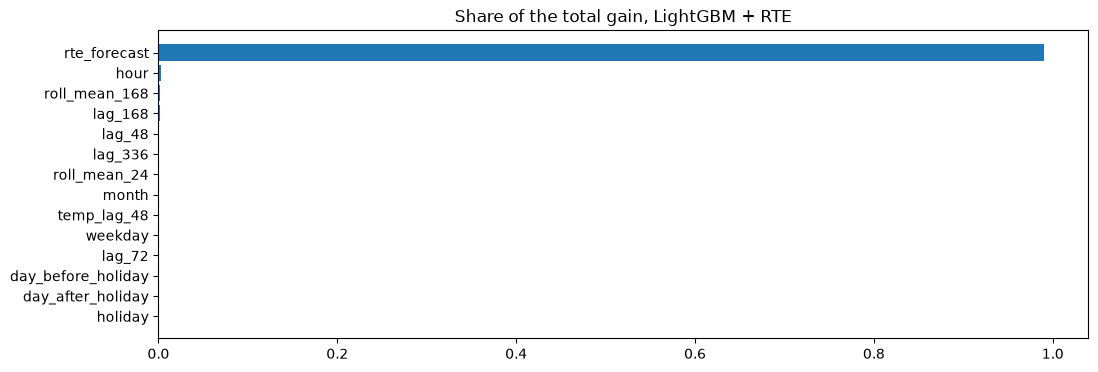

feature,gain
str,f64
"""rte_forecast""",0.99
"""hour""",0.002
"""roll_mean_168""",0.001
"""lag_168""",0.001
"""lag_48""",0.001


In [15]:
gain = model_rte.booster_.feature_importance("gain")
importance = pl.DataFrame({"feature": feature_cols(tables["persistence + RTE"]), "gain": gain / gain.sum()}).sort("gain")

plt.barh(importance["feature"], importance["gain"])
plt.title("Share of the total gain, LightGBM + RTE")
plt.show()
importance.sort("gain", descending=True).head(5).with_columns(pl.col("gain").round(3))

RTE's forecast takes 99 % of the gain, then hour. The model is really a correction of RTE.

### A.7 Too good to be true?

Beating the benchmark by far is a bug until proven otherwise (course rule). Here is what we checked.

In [16]:
# RTE's mean error (forecast - actual) per year: the bias LightGBM + RTE can learn
(
    df.filter(pl.col("date") <= TEST_END)
    .group_by(pl.col("date").dt.year().alias("year"))
    .agg((pl.col("rte_forecast_j1_mw") - pl.col("target")).mean().round(0).alias("RTE_bias_(MW)"))
    .sort("year")
)

year,RTE_bias_(MW)
i32,f64
2019,-228.0
2020,-115.0
2021,-227.0
2022,-574.0
2023,-1131.0
2024,-1146.0
2025,-973.0
2026,-1220.0


RTE's bias went from about -200 MW until 2021 to about -1,100 MW since 2023.

- Correcting RTE's usual error is legit: it's large, hour-dependent and the model learns it. It still keeps a
  -414 MW bias on the test (average of old and new bias).
- RTE before 12:00? Not verified. If it comes later, the gain isn't real.
- Consolidated data flatters us a bit vs real-time, probably small on lags of 48 h and more.
- No leak in the code: s + 48 everywhere, chronological splits, nothing tuned on the test.